# The baseline of the matched-filter search

Before the matched filter, the search divides each light curve by a **baseline**: a rolling median
over 20 × the template span (≈ 16 s), computed on block means of window/64 samples (0.25 s) and
linearly interpolated (`compute_baseline_and_sigma`, `decimate="auto"`). The σ-estimator notebook
(`sigma_estimator_study.ipynb`, section 4.3) found that this baseline makes the filter output of
*Gaussian* noise non-Gaussian, with excess kurtosis ≈ 1. The SNR tail is then heavy even when the noise
level is known exactly. A rolling median of red noise moves in steps (it switches between block
values), and the template, which has a non-zero mean, responds to steps.

The median was chosen for robustness: a dip or a glitch barely moves it, while a mean is pulled by both.
This notebook looks for a baseline that is **smooth (Gaussian tails) and still robust**, and compares
them where it matters: false-alarm rate and detection efficiency at equal FAR.

| | baseline | idea |
|---|---|---|
| **B0** | decimated rolling median (pipeline) | robust, steps |
| **B1** | exact rolling median (`decimate=1`) | reference; too slow for the injection study |
| **B2** | B0, then a running mean over window/4 of the decimated points | robust stage first, steps smoothed |
| **B3** | clipped running mean: block means more than 3σ from B0 are replaced by B0, then a running mean over the window | linear where nothing is clipped |
| **B4** | running mean over the window | linear reference, not robust |
| **B5** | B3 with a triangular kernel (two running means of window/2) | as B3, with weaker frequency sidelobes |

All searches use the **sliding** σ estimator (`empirical_filter_sigma(method="sliding")`, the outcome of
the σ notebook). For reference, the old pipeline (B0 with the block σ) is shown alongside.

Data: night 2026-08-19, four stars × MAGIC-2/LST-1/MAGIC-1, good-time windows, 5.24 ms bins, per-star
template bank. The setup is the same as in the σ notebook.

In [1]:
import time as _time
import warnings
from dataclasses import replace
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.ndimage import median_filter, uniform_filter1d
from scipy.special import ndtr
from scipy.stats import kurtosis
from IPython.display import display

from kbo_occultation import load_observation_log
from kbo_occultation.config import ORM_ARRAY
from kbo_occultation.observations.photometry import LightCurve
from kbo_occultation.analysis.mimic import (MimicConfig, star_bank, bank_instrument, bin_lightcurve,
                                            _template_duration, _telescope_results, _event_rows)
from kbo_occultation.analysis.matched_filter import (compute_baseline_and_sigma, sliding_matched_filter_snr,
                                                     empirical_filter_sigma, find_candidates)
from kbo_occultation.analysis.coincidence import coincidence_tolerance_s, accidental_coincidence_rate
from kbo_occultation.analysis.surrogates import phase_randomized_lightcurve
from kbo_occultation.analysis.noise_removal import star_fraction_for, threshold_for_far
from kbo_occultation.simulation.kinematics import (EARTH_SEMIMAJOR_AXIS_AU, ShadowKinematics,
                                                   shadow_velocity_opposition)

warnings.filterwarnings("ignore", category=RuntimeWarning)
pd.set_option("display.width", 250)
pd.set_option("display.max_columns", 40)

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
OUT = ROOT / "outputs" / "notebooks" / "baseline_study"
OUT.mkdir(parents=True, exist_ok=True)

QUICK = False                    # True: a few minutes; False: the full numbers quoted in the text
SEED = 0
N_SURR = 8 if QUICK else 30      # Gaussian surrogates per channel-run
N_INJ = 40 if QUICK else 150     # injections per channel-run, kind and variant
N_SHIFTS = 200
NIGHT = "2026-08-19"
FOCUS = ("HD170263", "A")
RADIUS = 100.0
SNR_FLOOR = 3.0
FAR_SINGLE, FAR_COINC = 10.0, 1.0

INK, MUTED, GRID = "#0b0b0b", "#52514e", "#e4e3df"
COLOR = {"B0 median": "#0b0b0b", "B1 exact median": "#9b9a96", "B2 median+smooth": "#2a78d6",
         "B3 clipped mean": "#1baf7a", "B4 running mean": "#eb6834", "B5 clipped triangle": "#8a5cd0",
         "old pipeline": "#c2408a"}
plt.rcParams.update({"figure.dpi": 100, "savefig.dpi": 140, "axes.titlesize": 10, "axes.labelsize": 9,
                     "legend.fontsize": 8})

def style(ax):
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)
    for side in ("left", "bottom"):
        ax.spines[side].set_color(MUTED)
    ax.tick_params(colors=MUTED, labelsize=8)
    ax.grid(color=GRID, lw=0.6)
    ax.set_axisbelow(True)
    return ax

def finish(fig, name):
    fig.tight_layout()
    fig.savefig(OUT / f"{name}.png", bbox_inches="tight")
    plt.show()

T_START = _time.time()

In [2]:
log = load_observation_log()
night = log.nights[NIGHT]
cfg = MimicConfig()
V = shadow_velocity_opposition(cfg.distance_au + EARTH_SEMIMAJOR_AXIS_AU)
FILTER = getattr(night, "optical_filter", None)
TEL = {ch: night.telescope(ch).name for ch in night.channels}
TTYPE = {ch: "LST" if TEL[ch].startswith("LST") else "MAGIC" for ch in night.channels}
_banks = {}
RUNS = {}
for star, obs in night.stars.items():
    for ch in obs.channels:
        key_b = (obs.name, TTYPE[ch])
        if key_b not in _banks:
            _banks[key_b] = star_bank(cfg, obs, V, bank_instrument(TEL[ch], FILTER))
        lc = obs.lightcurve(ch, good_time=True)
        RUNS[(star, ch)] = dict(obs=obs, binned=bin_lightcurve(lc, 10), bank=_banks[key_b],
                                sf=star_fraction_for(obs, TTYPE[ch]))
STARS = list(night.stars)
RUN_INDEX = {k: i for i, k in enumerate(RUNS)}
DUR = _template_duration(next(iter(RUNS.values()))["bank"])
WIN_S = 20.0 * DUR
TOL = coincidence_tolerance_s(ORM_ARRAY, ShadowKinematics(V), DUR)
LIVE = {s: RUNS[(s, "A")]["binned"].time[-1] - RUNS[(s, "A")]["binned"].time[0] for s in STARS}
print(f"{len(RUNS)} channel-runs, {sum(LIVE.values())/60:.1f} min per telescope; template span {DUR:.3f} s, "
      f"baseline/σ window {WIN_S:.1f} s")

12 channel-runs, 10.0 min per telescope; template span 0.798 s, baseline/σ window 16.0 s


## The baselines

All candidates except B1 work on the same decimated grid as the pipeline: block means of window/64
samples (0.25 s), a filter over the window on that grid, and linear interpolation back to every sample.
The cost is the same for all of them, and the window is the same 16 s.

,baseline,5.24 ms [s],native [s]
0,B0 median,0.005,0.026
1,B1 exact median,3.641,NaN
2,B2 median+smooth,0.001,0.004
3,B3 clipped mean,0.002,0.005
4,B4 running mean,0.000,0.003
5,B5 clipped triangle,0.002,0.005


median filter-output σ relative to B0 (real data, 100 m template):


,B0 median,B2 median+smooth,B3 clipped mean,B4 running mean,B5 clipped triangle
median over runs,1.0,1.019,1.176,1.185,0.974


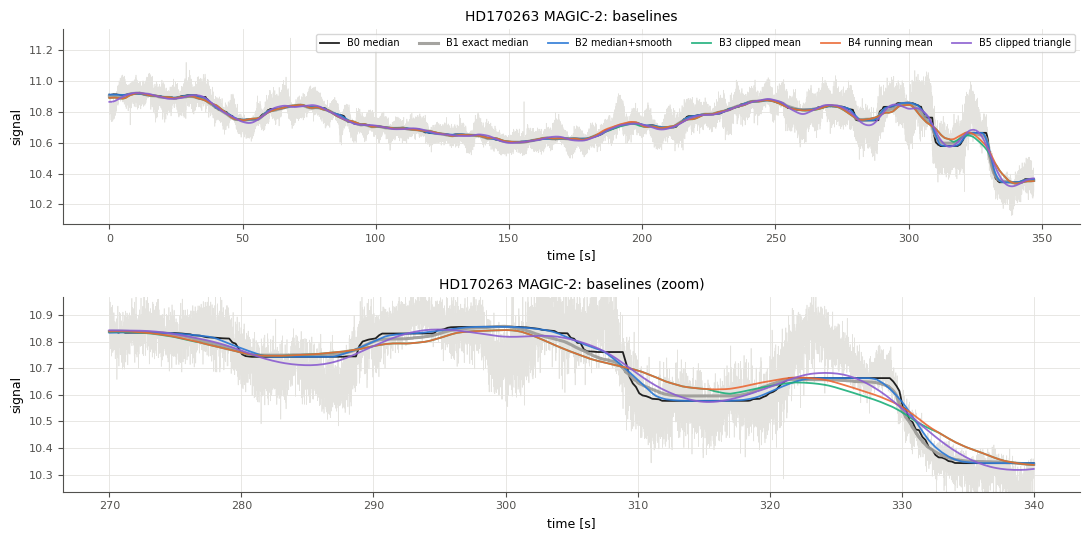

In [3]:
def surrogate(key, k):
    return phase_randomized_lightcurve(RUNS[key]["binned"], np.random.default_rng([SEED, RUN_INDEX[key], k]))

def filter_output(lc, tt_, ti_, base):
    """(MatchedFilterResult, a = corr / template norm) with a given baseline."""
    M = len(np.arange(tt_.min(), tt_.max(), lc.dt))
    mf = sliding_matched_filter_snr(lc.time, lc.signal, tt_, ti_, baseline=base, sigma=np.ones_like(base),
                                    amp_sigma=np.ones(len(lc.time) - M + 1))
    return mf, mf.snr

def _decimated(lc):
    dt = lc.dt
    w = max(int(round(WIN_S / dt)), 1)
    stride = max(1, w // 64)
    nb = len(lc.signal) // stride
    sb = lc.signal[:nb * stride].reshape(-1, stride).mean(axis=1)
    tb = lc.time[:nb * stride].reshape(-1, stride).mean(axis=1)
    return sb, tb, max(w // stride, 3)

def b0_median(lc):
    return compute_baseline_and_sigma(lc.time, lc.signal, DUR)[0]

def b1_exact(lc):
    return compute_baseline_and_sigma(lc.time, lc.signal, DUR, decimate=1)[0]

def b2_median_smooth(lc, frac=4):
    sb, tb, wd = _decimated(lc)
    med = median_filter(sb, size=wd, mode="reflect")
    return np.interp(lc.time, tb, uniform_filter1d(med, size=max(wd // frac, 1), mode="reflect"))

def b3_clipped_mean(lc, k=3.0):
    sb, tb, wd = _decimated(lc)
    med = median_filter(sb, size=wd, mode="reflect")
    dev = sb - med
    s = 1.4826 * median_filter(np.abs(dev), size=wd, mode="reflect")
    clipped = np.where(np.abs(dev) > k * s, med, sb)
    return np.interp(lc.time, tb, uniform_filter1d(clipped, size=wd, mode="reflect"))

def b5_clipped_triangle(lc, k=3.0):
    sb, tb, wd = _decimated(lc)
    med = median_filter(sb, size=wd, mode="reflect")
    dev = sb - med
    s = 1.4826 * median_filter(np.abs(dev), size=wd, mode="reflect")
    clipped = np.where(np.abs(dev) > k * s, med, sb)
    half = max(wd // 2, 1)
    tri = uniform_filter1d(uniform_filter1d(clipped, size=half, mode="reflect"), size=half, mode="reflect")
    return np.interp(lc.time, tb, tri)

def b4_mean(lc):
    sb, tb, wd = _decimated(lc)
    return np.interp(lc.time, tb, uniform_filter1d(sb, size=wd, mode="reflect"))

BASELINES = {"B0 median": b0_median, "B1 exact median": b1_exact, "B2 median+smooth": b2_median_smooth,
             "B3 clipped mean": b3_clipped_mean, "B4 running mean": b4_mean, "B5 clipped triangle": b5_clipped_triangle}
SEARCH = ["B0 median", "B2 median+smooth", "B3 clipped mean", "B4 running mean", "B5 clipped triangle"]   # B1 is too slow

# speed on the longest run (5.24 ms) and on its native 0.524 ms version
lc5 = RUNS[FOCUS]["binned"]
lcn = RUNS[FOCUS]["obs"].lightcurve(FOCUS[1], good_time=True)
rows = []
for name, fn in BASELINES.items():
    row = {"baseline": name}
    for lab, lc_ in (("5.24 ms", lc5), ("native", lcn)):
        if name == "B1 exact median" and lab == "native":
            row[f"{lab} [s]"] = np.nan
            continue
        t_ = _time.time(); fn(lc_); row[f"{lab} [s]"] = _time.time() - t_
    rows.append(row)
display(pd.DataFrame(rows).round(3))

# how much noise each baseline lets into the filter output: median sliding σ of the 100 m output on the
# real data, relative to B0 (a baseline with frequency sidelobes leaves more 0.04-0.2 Hz wander in)
rows = []
for key, rr in RUNS.items():
    tt_, ti_ = rr["bank"][RADIUS]
    lc = rr["binned"]
    row = {"star": key[0], "telescope": TEL[key[1]]}
    for n in [b for b in BASELINES if b != "B1 exact median"]:
        mf, a = filter_output(lc, tt_, ti_, BASELINES[n](lc))
        row[n] = np.median(empirical_filter_sigma(a, max(int(round(WIN_S / lc.dt)), len(mf.template_delta)), method="sliding"))
    rows.append(row)
LEAK = pd.DataFrame(rows)
for n in [b for b in BASELINES if b not in ("B1 exact median", "B0 median")]:
    LEAK[n] = LEAK[n] / LEAK["B0 median"]
LEAK["B0 median"] = 1.0
print("median filter-output σ relative to B0 (real data, 100 m template):")
display(LEAK.drop(columns=["star", "telescope"]).median().round(3).to_frame("median over runs").T)

fig, axs = plt.subplots(2, 1, figsize=(11, 5.5))
t0 = lc5.time[0]
for ax, (z0, z1) in zip(axs, ((0, 347), (270, 340))):
    style(ax)
    m = (lc5.time - t0 >= z0) & (lc5.time - t0 <= z1)
    ax.plot(lc5.time[m] - t0, lc5.signal[m], color=GRID, lw=0.5, zorder=0)
    for name, fn in BASELINES.items():
        ax.plot(lc5.time[m] - t0, fn(lc5)[m], color=COLOR[name], lw=1.3 if name != "B1 exact median" else 2.2,
                alpha=0.9, label=name)
    ax.set(xlabel="time [s]", ylabel="signal", title=f"{FOCUS[0]} {TEL[FOCUS[1]]}: baselines" + (" (zoom)" if z0 else ""))
    if z0:
        lo, hi = np.percentile(lc5.signal[m], [1, 99]); ax.set_ylim(lo, hi)
axs[0].legend(ncol=6, fontsize=7, loc="upper right")
finish(fig, "01_baselines")

## 1. Gaussian noise in, Gaussian SNR out?

On stationary Gaussian surrogates (`phase_randomized_lightcurve`, same spectrum as each run), a linear
baseline gives a Gaussian filter output. We measure the excess kurtosis of the 100 m filter output and the
tail of the SNR with the *true* σ (the pooled robust σ of that baseline's output over the run's
surrogates), for all 12 channel-runs.

111 s


kurtosis       std/MAD      
                        mean   std    mean   std
baseline                                        
B0 median               0.51  0.71    1.18  0.21
B1 exact median         0.26  0.57    1.10  0.15
B2 median+smooth        0.37  0.60    1.12  0.14
B3 clipped mean        -0.14  0.33    0.99  0.07
B4 running mean        -0.17  0.32    0.99  0.07
B5 clipped triangle     0.01  0.40    1.01  0.07

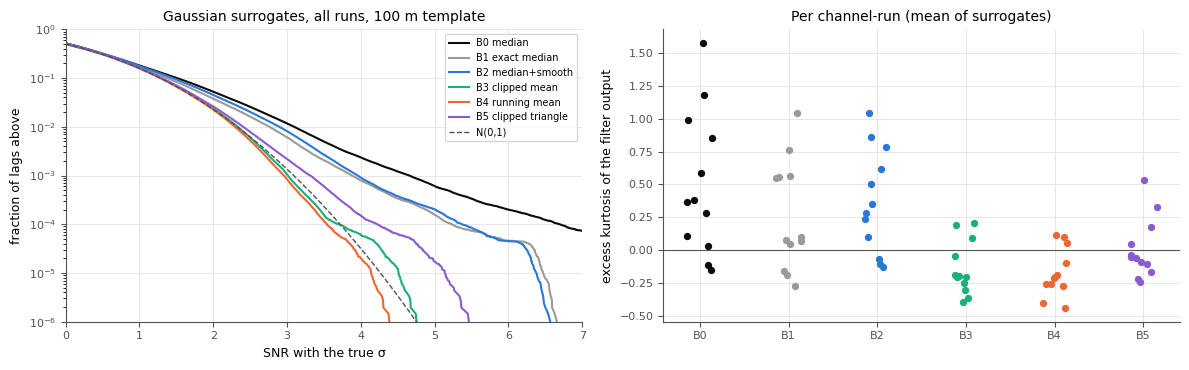

In [4]:
t_ = _time.time()
rows, tails = [], {n: [] for n in BASELINES}
for key, rr in RUNS.items():
    tt_, ti_ = rr["bank"][RADIUS]
    pooled = {n: [] for n in BASELINES}
    for k in range(min(N_SURR, 6)):
        sur = surrogate(key, k)
        for n, fn in BASELINES.items():
            a = filter_output(sur, tt_, ti_, fn(sur))[1]
            pooled[n].append(a)
            rows.append({"star": key[0], "telescope": TEL[key[1]], "baseline": n, "kurtosis": kurtosis(a),
                         "std/MAD": np.std(a) / (1.4826 * np.median(np.abs(a)))})
    for n, lst in pooled.items():
        a = np.concatenate(lst)
        tails[n].append(a / (1.4826 * np.median(np.abs(a))))
GAUSS = pd.DataFrame(rows)
print(f"{_time.time() - t_:.0f} s")
display(GAUSS.groupby("baseline")[["kurtosis", "std/MAD"]].agg(["mean", "std"]).round(2))

fig, axs = plt.subplots(1, 2, figsize=(12, 3.8))
ax = style(axs[0])
xs = np.linspace(0, 7, 141)
for n, lst in tails.items():
    z = np.sort(np.concatenate(lst))
    ax.semilogy(z, 1.0 - np.arange(len(z)) / len(z), color=COLOR[n], lw=1.5, label=n)
ax.semilogy(xs, ndtr(-xs), color=MUTED, ls="--", lw=1, label="N(0,1)")
ax.set(xlim=(0, 7), ylim=(1e-6, 1), xlabel="SNR with the true σ", ylabel="fraction of lags above",
       title="Gaussian surrogates, all runs, 100 m template")
ax.legend(fontsize=7)
ax = style(axs[1])
piv = GAUSS.pivot_table(index=["star", "telescope"], columns="baseline", values="kurtosis")
for i, n in enumerate(BASELINES):
    ax.scatter(np.full(len(piv), i) + np.random.default_rng(i).uniform(-0.15, 0.15, len(piv)), piv[n],
               color=COLOR[n], s=18)
ax.set_xticks(range(len(BASELINES))); ax.set_xticklabels([n.split(" ", 1)[0] for n in BASELINES])
ax.axhline(0, color=MUTED, lw=0.8)
ax.set(ylabel="excess kurtosis of the filter output", title="Per channel-run (mean of surrogates)")
finish(fig, "02_gaussianity")

## 2. Robustness: is the event or a glitch pulling the baseline?

**Event pull.** A noiseless event is injected into a flat light curve, and the baseline is computed on
the injected series. If the baseline follows the
dip, the residual loses depth. The table gives the peak filter output relative to that with the true
(event-free) baseline, for templates of 50–1000 m at the full stellar depth (star fraction 1, a 0.03 mas
star).

**Glitches.** Two kinds are added to the real HD170263 light curves: single-bin spikes (+30 % of the
flux) and 2 s positive excursions (+3 %, like the DC excursions of the target pixel). Both are bright,
so they cannot look like a dip themselves, but a baseline pulled *up* by them puts the neighbouring data
*below* the baseline: a fake dip. We record the largest dip SNR between 1.5 and 10 s from each glitch,
normalised by the uninjected run's sliding σ, minus the same quantity without the glitch.

In [5]:
from kbo_occultation.analysis.mimic import search_templates
cfg03 = MimicConfig(template_radii_m=(50.0, 100.0, 300.0, 1000.0))
bank03 = search_templates(cfg03, V, star_mas=0.03, instrument=bank_instrument(TEL["A"], FILTER))
dt5 = lc5.dt
tgrid = np.arange(0, 120.0, dt5)
wander = np.ones_like(tgrid)                 # flat: only the event can move the baseline
rows = []
for R, (tt_, ti_) in bank03.items():
    t0e = 60.0 + 0.37 * dt5
    offs = (np.arange(20) + 0.5) / 20 - 0.5
    dip = (np.interp(tgrid[:, None] + offs[None, :] * dt5 - t0e, tt_, ti_, left=1.0, right=1.0)).mean(axis=1)
    lc_ev = LightCurve(tgrid, wander * dip, meta={})
    true = filter_output(lc_ev, tt_, ti_, wander)[1]
    j = slice(int((t0e - 1.0) / dt5), int((t0e + 1.0) / dt5))
    ref = true[j].max()                          # a dip gives a positive filter output
    row = {"radius [m]": R, "depth": 1 - dip.min()}
    for n in BASELINES:
        row[n] = filter_output(lc_ev, tt_, ti_, BASELINES[n](lc_ev))[1][j].max() / ref
    rows.append(row)
PULL = pd.DataFrame(rows)
display(PULL.round(4))

rng = np.random.default_rng(SEED + 3)
rows = []
for c in night.channels:
    rr = RUNS[(FOCUS[0], c)]
    lc = rr["binned"]; tt_, ti_ = rr["bank"][RADIUS]
    sig0 = {}
    for n in SEARCH:
        mf, a = filter_output(lc, tt_, ti_, BASELINES[n](lc))
        sig0[n] = (mf, a, empirical_filter_sigma(a, max(int(round(WIN_S / dt5)), len(mf.template_delta)), method="sliding"))
    for kind in ("spike", "excursion 2 s"):
        for tg in rng.uniform(lc.time[0] + 15, lc.time[-1] - 15, 12):
            s = lc.signal.copy()
            if kind == "spike":
                s[np.searchsorted(lc.time, tg)] *= 1.30
            else:
                s[(lc.time >= tg) & (lc.time < tg + 2.0)] *= 1.03
            lcg = LightCurve(lc.time, s, meta=lc.meta)
            for n in SEARCH:
                mf, a0, sg = sig0[n]
                a = filter_output(lcg, tt_, ti_, BASELINES[n](lcg))[1]
                d = np.abs(mf.time - tg)
                near = (d >= 1.5) & (d <= 10.0)
                rows.append({"telescope": TEL[c], "glitch": kind, "baseline": n,
                             "fake dip SNR": (a[near] / sg[near]).max() - (a0[near] / sg[near]).max()})
GLITCH = pd.DataFrame(rows)
display(GLITCH.groupby(["glitch", "baseline"])["fake dip SNR"].agg(["mean", "max"]).unstack(0).round(2))

,radius [m],depth,B0 median,B1 exact median,B2 median+smooth,B3 clipped mean,B4 running mean,B5 clipped triangle
0,50.0,0.0038,1.0,1.0,1.0,1.0,0.9939,1.0
1,100.0,0.0150,1.0,1.0,1.0,1.0,0.9943,1.0
2,300.0,0.1196,1.0,1.0,1.0,1.0,0.9953,1.0
3,1000.0,0.6080,1.0,1.0,1.0,1.0,0.9965,1.0


mean                 max      
glitch              excursion 2 s spike excursion 2 s spike
baseline                                                   
B0 median                    0.31  0.00          1.94  0.10
B2 median+smooth             0.24  0.00          1.55  0.06
B3 clipped mean              0.19  0.00          1.56  0.03
B4 running mean              0.62  0.01          3.17  0.05
B5 clipped triangle          0.26  0.00          1.41  0.07

## 3. False-alarm rates and efficiency at equal FAR

The full search on all 12 channel-runs (real data and `N_SURR` surrogates each): per-star bank, sliding
σ, candidates above SNR 3 with the best template per time. Single-telescope thresholds come from real data
and surrogates, and 2-of-3 thresholds from time slides and surrogates. Efficiency is measured with
additive SNR-6 injections of the 100 m template (bin-averaged at a random sub-bin phase). **The baseline
is recomputed on the injected light curve**, so a baseline that follows the event pays for it. Each
variant uses its own threshold at the same FAR.

searches: 80 s, 6040 candidates


,single real thr @10/h,single real thr @30/h,single surrogate thr @10/h,2-of-3 timeslide thr @1/h,2-of-3 surrogate thr @1/h
variant,,,,,
old pipeline,7.55,4.35,5.92,4.04,3.91
B0 median,6.03,4.11,4.54,3.58,3.31
B2 median+smooth,5.73,3.94,4.03,3.38,3.15
B3 clipped mean,4.84,3.20,3.38,3.00,3.00
B4 running mean,3.58,3.00,3.26,3.00,3.00
B5 clipped triangle,5.53,3.84,3.75,3.06,3.00


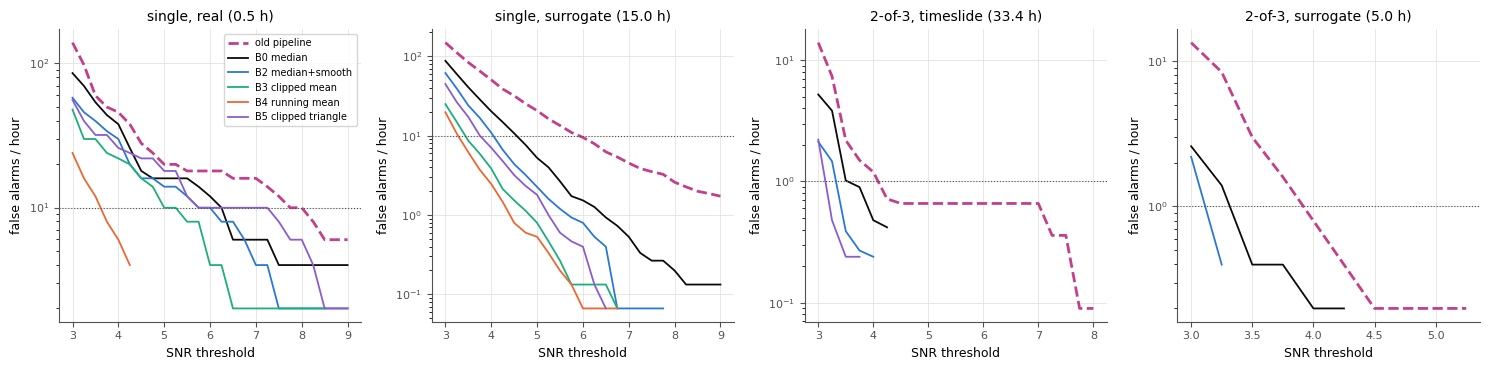

In [6]:
VARIANTS = {"old pipeline": ("B0 median", "blocks")}
VARIANTS.update({n: (n, "sliding") for n in SEARCH})

def outputs(lc, bank, base):
    return {R: filter_output(lc, tt_, ti_, base) for R, (tt_, ti_) in bank.items()}

def amp_sigma(mf, a, method):
    return empirical_filter_sigma(a, max(int(round(WIN_S / mf.dt_s)), len(mf.template_delta)), method=method)

def candidates(outs, method, thr=SNR_FLOOR):
    best = []
    for R, (mf, a) in outs.items():
        s = amp_sigma(mf, a, method)
        for c in find_candidates(replace(mf, snr=a / s, amp_sigma=s), snr_threshold=thr, chi2_weighting="empirical"):
            best.append({"time_s": c.time_s, "snr": c.snr, "chi2_reduced": c.chi2_reduced, "radius_m": R})
    kept = []
    for row in sorted(best, key=lambda x: -x["snr"]):
        if all(abs(row["time_s"] - k_["time_s"]) >= DUR for k_ in kept):
            kept.append(row)
    return kept

t_ = _time.time()
CAND = []
for key, rr in RUNS.items():
    for kind, k in [("real", -1)] + [("surrogate", k) for k in range(N_SURR)]:
        lc = rr["binned"] if kind == "real" else surrogate(key, k)
        outs_by_base = {n: outputs(lc, rr["bank"], BASELINES[n](lc)) for n in SEARCH}
        for var, (bname, smeth) in VARIANTS.items():
            for c in candidates(outs_by_base[bname], smeth):
                CAND.append({"star": key[0], "channel": key[1], "kind": kind, "k": k, "est": var, **c})
CAND = pd.DataFrame(CAND)
print(f"searches: {_time.time() - t_:.0f} s, {len(CAND)} candidates")

H_SINGLE = {"real": sum(LIVE.values()) * 3 / 3600, "surrogate": sum(LIVE.values()) * 3 * N_SURR / 3600}
H_COINC = {"timeslide": sum(LIVE.values()) * N_SHIFTS / 3600, "surrogate": sum(LIVE.values()) * N_SURR / 3600}

def coincidences(cand, kinds_k, ests):
    ev = []
    for est in ests:
        for star in STARS:
            for kind, k in kinds_k:
                sub = cand[(cand.est == est) & (cand.star == star) & (cand.kind == kind) & (cand.k == k)]
                per_ch = {c: (sub[sub.channel == c].to_dict("records"), LIVE[star]) for c in night.channels}
                res = _telescope_results(per_ch)
                if kind == "real":
                    acc = accidental_coincidence_rate(res, TOL, LIVE[star], n_shifts=N_SHIFTS,
                                                      min_shift_s=max(5.0, 3.0 * TOL), seed=SEED)
                    ev += [{"est": est, "kind": "timeslide", "min_snr": s} for s in acc.event_min_snr]
                else:
                    ev += [{"est": est, "kind": kind, "min_snr": e["min_snr"]} for e in _event_rows(res, TOL)]
    return pd.DataFrame(ev, columns=["est", "kind", "min_snr"])

EV = coincidences(CAND, [("real", -1)] + [("surrogate", k) for k in range(N_SURR)], list(VARIANTS))

rows = []
for var in VARIANTS:
    row = {"variant": var}
    for kind in ("real", "surrogate"):
        s = CAND[(CAND.est == var) & (CAND.kind == kind)]["snr"].to_numpy()
        row[f"single {kind} thr @10/h"] = threshold_for_far(s, H_SINGLE[kind], FAR_SINGLE, SNR_FLOOR)
        if kind == "real":
            row["single real thr @30/h"] = threshold_for_far(s, H_SINGLE[kind], 30.0, SNR_FLOOR)
    for kind in ("timeslide", "surrogate"):
        s = EV[(EV.est == var) & (EV.kind == kind)]["min_snr"].to_numpy()
        row[f"2-of-3 {kind} thr @1/h"] = threshold_for_far(s, H_COINC[kind], FAR_COINC, SNR_FLOOR)
    rows.append(row)
THR = pd.DataFrame(rows).set_index("variant")
display(THR.round(2))

SNR_GRID = np.round(np.arange(3.0, 9.01, 0.25), 2)
fig, axs = plt.subplots(1, 4, figsize=(15, 3.8))
for ax, (scope, kind) in zip(axs, (("single", "real"), ("single", "surrogate"), ("2-of-3", "timeslide"), ("2-of-3", "surrogate"))):
    style(ax)
    for var in VARIANTS:
        if scope == "single":
            s, h = CAND[(CAND.est == var) & (CAND.kind == kind)]["snr"].to_numpy(), H_SINGLE[kind]
        else:
            s, h = EV[(EV.est == var) & (EV.kind == kind)]["min_snr"].to_numpy(), H_COINC[kind]
        rate = np.array([(s >= g).sum() / h for g in SNR_GRID])
        ax.semilogy(SNR_GRID, np.where(rate > 0, rate, np.nan), color=COLOR[var], lw=2 if var == "old pipeline" else 1.3,
                    ls="--" if var == "old pipeline" else "-", label=var)
    ax.axhline(FAR_SINGLE if scope == "single" else FAR_COINC, color=MUTED, lw=0.8, ls=":")
    ax.set(xlabel="SNR threshold", ylabel="false alarms / hour", title=f"{scope}, {kind} ({h:.1f} h)")
axs[0].legend(fontsize=7)
finish(fig, "03_far")

In [7]:
SUB = 20

def event_signal(lc, key, t0, tt_, ti_):
    """Additive bin-averaged event (fraction of the flux) and its sample range."""
    j = int(np.searchsorted(lc.time, t0))
    M = int(round((tt_.max() - tt_.min()) / lc.dt))
    lo, hi = max(j - M, 0), min(j + M, len(lc.time))
    offs = (np.arange(SUB) + 0.5) / SUB - 0.5
    tb = lc.time[lo:hi, None] + offs[None, :] * lc.dt
    return lo, hi, RUNS[key]["sf"] * (np.interp(tb - t0, tt_, ti_, left=1.0, right=1.0) - 1.0).mean(axis=1)

def inject(key, kind, k, n, rng, target=6.0):
    rr = RUNS[key]
    lc = rr["binned"] if kind == "real" else surrogate(key, k)
    tt_, ti_ = rr["bank"][RADIUS]
    base_ref = b0_median(lc)
    mf_ref, a_ref = filter_output(lc, tt_, ti_, base_ref)
    s_ref = 1.4826 * np.median(np.abs(a_ref))
    M = len(mf_ref.template_delta)
    t0s = rng.uniform(lc.time[0] + 1.5 * DUR, lc.time[-1] - 1.5 * DUR, n)
    # scale: SNR `target` against s_ref for the ideal response (baseline fixed)
    peaks = []
    for t0 in t0s[:20]:
        lo, hi, s = event_signal(lc, key, t0, tt_, ti_)
        sig = lc.signal.copy(); sig[lo:hi] += base_ref[lo:hi] * s
        peaks.append((filter_output(LightCurve(lc.time, sig, meta=lc.meta), tt_, ti_, base_ref)[1] - a_ref).max())
    scale = target * s_ref / np.mean(peaks)
    half = int(round(0.1 / lc.dt))
    out = []
    for t0 in t0s:
        lo, hi, s = event_signal(lc, key, t0, tt_, ti_)
        sig = lc.signal.copy(); sig[lo:hi] += base_ref[lo:hi] * s * scale
        lci = LightCurve(lc.time, sig, meta=lc.meta)
        i_c = int(np.searchsorted(lc.time, t0)) - M // 2
        win = slice(max(i_c - half, 0), i_c + half + 1)
        row = {"star": key[0], "channel": key[1], "kind": kind}
        bases = {n: BASELINES[n](lci) for n in SEARCH}
        for var, (bname, smeth) in VARIANTS.items():
            mf, a = filter_output(lci, tt_, ti_, bases[bname])
            sg = amp_sigma(mf, a, smeth)
            row[var] = (a[win] / sg[win]).max()
        out.append(row)
    return out

t_ = _time.time()
rng = np.random.default_rng(SEED + 7)
INJ = pd.DataFrame([r for key in RUNS for kind, k in (("real", -1), ("surrogate", 0)) for r in inject(key, kind, k, N_INJ, rng)])
print(f"{len(INJ)} injections in {_time.time() - t_:.0f} s")

rows = []
for var in VARIANTS:
    row = {"variant": var}
    for kind in ("real", "surrogate"):
        x = INJ[INJ.kind == kind][var]
        row[f"{kind} mean SNR"] = x.mean()
        row[f"eff. {kind} @10/h"] = (x >= THR.loc[var, f"single {kind} thr @10/h"]).mean()
    row["eff. real @30/h"] = (INJ[INJ.kind == "real"][var] >= THR.loc[var, "single real thr @30/h"]).mean()
    rows.append(row)
EFF = pd.DataFrame(rows).set_index("variant")
SUMMARY = THR.join(EFF)
SUMMARY["surrogate kurtosis"] = [GAUSS[GAUSS.baseline == VARIANTS[v][0]]["kurtosis"].mean() for v in SUMMARY.index]
display(SUMMARY.T.round(3))
SUMMARY.to_csv(OUT / "summary.csv")
print(f"notebook ran in {(_time.time() - T_START)/60:.1f} min (QUICK = {QUICK})")

3600 injections in 211 s


variant,old pipeline,B0 median,B2 median+smooth,B3 clipped mean,B4 running mean,B5 clipped triangle
single real thr @10/h,7.548,6.035,5.729,4.837,3.578,5.528
single real thr @30/h,4.350,4.112,3.943,3.204,3.000,3.836
single surrogate thr @10/h,5.918,4.542,4.027,3.380,3.264,3.753
2-of-3 timeslide thr @1/h,4.036,3.576,3.378,3.000,3.000,3.058
2-of-3 surrogate thr @1/h,3.909,3.305,3.152,3.000,3.000,3.000
real mean SNR,6.732,6.348,6.016,5.087,4.962,6.345
eff. real @10/h,0.338,0.477,0.488,0.488,0.643,0.569
surrogate mean SNR,6.618,6.235,6.024,5.186,5.237,6.597
eff. surrogate @10/h,0.532,0.722,0.775,0.771,0.795,0.872
eff. real @30/h,0.736,0.741,0.734,0.713,0.728,0.783


notebook ran in 7.7 min (QUICK = False)


## Conclusions

Numbers from the full run (`QUICK = False`: 30 surrogates and 150 injections per channel-run and kind), night
2026-08-19, 10 min of good time per telescope.

1. **Linear baselines keep Gaussian noise Gaussian.** Excess kurtosis of the filter output on Gaussian
   surrogates: B0 (pipeline median) 0.51 ± 0.71, B1 exact median 0.26, B2 smoothed median 0.37, B3/B4
   (box means) −0.14/−0.17, **B5 clipped triangle 0.01 ± 0.40**. std/MAD falls from 1.18 to 1.01.
2. **The kernel shape matters.** The box-kernel means (B3, B4) let ~18 % more noise into the filter output
   than the median, because their frequency sidelobes pass the 0.04–0.2 Hz wander that dominates it. The
   triangular kernel (B5) passes 3 % *less* than the median, so B5 keeps the SNR (mean injected SNR 6.35
   vs 6.35 for B0) while B3/B4 lose ~20 %.
3. **Robustness.**
   * Events up to 1000 m at full depth do not pull B5 (recovered amplitude 1.000), nor any of the
     robust baselines; the plain mean loses 0.4–0.6 %.
   * Next to 2 s +3 % excursions B5 makes the smallest worst-case fake dip (SNR 1.41 vs 1.94 for B0;
     3.17 for the plain mean). Single-bin spikes are harmless for all of them.
4. **False alarms and efficiency at equal FAR** (all with the sliding σ):
   * Efficiency of SNR-6 injections, B5 vs B0 vs the old pipeline:
     * real data at 10/h: 0.57 vs 0.48 vs 0.34;
     * real data at 30/h: 0.78 vs 0.74 vs 0.74;
     * surrogates at 10/h: 0.87 vs 0.72 vs 0.53.
   * The 2-of-3 time-slide threshold at 1/h drops from 4.04 (old) and 3.58 (B0) to 3.06 (B5).
   * Where a threshold reads 3.00 it sits at the candidate floor: fewer false alarms than allowed even
     at SNR 3, so it is an upper limit.
   * The plain running mean (B4) has the best real 10/h efficiency (0.64), but it is not robust to
     excursions and its thresholds are floor-limited, so it is not chosen.
5. **Choice: B5**, now `compute_baseline_and_sigma(method="clipped_triangle")`. Points more than 3 robust σ
   from the rolling median are replaced by the median, and the rest is smoothed with a triangular kernel of
   full width the 16 s window, on the same 0.25 s decimated grid as before (same cost).

   Together with the sliding σ, it raises the efficiency at equal single-telescope FAR by ×1.7 on real
   data (10/h) and ×1.6 on surrogates relative to the old pipeline. This is one night. The confirmation on
   all nights is the mimic and noise-removal comparison that comes next.